<div style="background:linear-gradient(135deg,#4F46E5 0%,#06B6D4 100%);padding:28px 32px;border-radius:14px;color:white;">
<h1 style="margin:0;color:white;">📱 Mobile Phone Price Prediction</h1>
<p style="margin:6px 0 0 0;font-size:16px;color:#E0F2FE;">Feature extraction, price modelling and deployment-ready inference &nbsp;|&nbsp; Project 4 · Data Science / Machine Learning</p>
</div>

## Objective
An organisation that sells mobile phones wants to understand **which phone features drive price** and to build a model that can **predict the price of a phone from its specifications**.

This notebook also serves as the project report, bringing together the data exploration, visualizations, feature analysis, model evaluation, findings, recommendations, and deployment example.

## Workflow
| Step | Stage | What happens |
|---|---|---|
| 1 | Data exploration | Shape, types, missing values, raw distributions |
| 2 | Preprocessing | Clean prices, remove corrupt rows, fix unit errors, engineer features |
| 3 | Feature extraction | Correlation, F-test, mutual information, ANOVA (η²), PCA |
| 4 | Model building | Leakage-free split, baseline vs tuned models, cross-validation |
| 5 | Evaluation | MAE, RMSE, R² on unseen phone models |
| 6 | Feature importance | Which specs move the price most |
| 7 | Business insights & deployment | Recommendations, saved model, live prediction function |

### ✅ Corrections made to the original notebook
| # | Issue in original | Impact | Fix applied |
|---|---|---|---|
| 1 | `Prize` column is text (`"7,299"`) and was never converted | **Crash** at the correlation heat-map (`ValueError: could not convert string to float`) | Commas stripped and column converted to numbers |
| 2 | `color="slate-gray"` is not a valid colour | **Crash** in the residual plot | Valid colour used |
| 3 | `Unnamed: 0` (row index) counted as a column | Duplicate check always said "0 duplicates" | Dropped before duplicate check |
| 4 | Heights flagged with hard-coded 14–25 cm limits (comment said "IQR") | Valid small phones (Nokia C01 Plus, LAVA Z21) were overwritten | Range widened to 10–25 cm |
| 5 | Moto G62 height of `41.94` replaced with the median | Lost real information | `41.94 cm` is `16.51 in` converted twice, so it is now divided by 2.54 → `16.51 cm` |
| 6 | Random row split while the same phone model appears in several colours | Test rows had identical twins in training, so scores were **over-optimistic** | Split and tuning now grouped by phone model |
| 7 | Best model chosen using **test** scores | Test-set leakage | Chosen using cross-validation on training data only |
| 8 | Linear, Ridge and Tree models defined but never run; F-test, mutual info and PCA imported but never used | Workflow promised in the objective was incomplete | All models compared; F-test, MI and PCA added |
| 9 | Raw-data plot drew `Prize` as 158 unreadable bars | Unreadable chart | Replaced with histograms |
| 10 | Brand `"I"` (from "I Kall"), Apple/Google chips labelled "MediaTek" | Wrong categories fed to model | Brand and chipset mapping corrected |
| 11 | Hard-coded `C:\Users\DELL\...` path; deprecated seaborn `palette` usage; no input checks on inference | Fails on any other machine | Configurable path, modern seaborn, validated inference |
| 12 | Business recommendations (step 7) missing | Incomplete deliverable | Data-driven insights section added |

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression, f_regression
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------- Configuration ----------
RANDOM_STATE = 42
# Put the CSV next to this notebook, or edit the list below with your own location.
DATA_CANDIDATES = [
    "Processed_Flipdata1.csv",
    r"C:\Users\DELL\Downloads\Processed_Flipdata1.csv",
]

# ---------- Visual theme ----------
PALETTE = ["#4F46E5", "#06B6D4", "#F59E0B", "#10B981", "#EF4444", "#8B5CF6", "#EC4899"]
sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.0)
plt.rcParams.update({
    "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "grid.alpha": 0.35, "figure.facecolor": "white",
})
pd.set_option("display.max_columns", 30)

def rupee_axis(ax, axis="y"):
    """Format an axis as Indian rupees, e.g. ₹15,000."""
    fmt = mtick.FuncFormatter(lambda v, _: f"₹{v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def banner(text, color="#4F46E5"):
    display(Markdown(f'<div style="background:{color};color:white;padding:10px 16px;border-radius:8px;'
                     f'font-weight:600;font-size:15px;">{text}</div>'))

def regression_scores(y_true, y_pred):
    return {"MAE (₹)": mean_absolute_error(y_true, y_pred),
            "RMSE (₹)": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R²": r2_score(y_true, y_pred)}

print("Libraries loaded and theme applied.")

Libraries loaded and theme applied.


## 1. Data Exploration

In [2]:
data_path = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Dataset not found. Place 'Processed_Flipdata1.csv' next to this notebook "
                            "or add its location to DATA_CANDIDATES in the Setup cell.")

df_raw = pd.read_csv(data_path)
df_raw.columns = df_raw.columns.str.strip()
# 'Unnamed: 0' is just the old row number - it is not a phone attribute.
df_raw = df_raw.drop(columns=[c for c in df_raw.columns if c.startswith("Unnamed")])

print(f"Loaded: {data_path}")
print(f"Shape (rows, columns): {df_raw.shape}")
df_raw.head(10)

Loaded: Processed_Flipdata1.csv
Shape (rows, columns): (541, 11)


,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
5,Infinix HOT 30i,Glacier Blue,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
6,Infinix HOT 30i,Mirror Black,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
7,Infinix HOT 30i,Diamond White,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
8,Infinix HOT 30i,Diamond White,64,4,5000,50MP,5MP,1,16.76,G37,"7,999"
9,Infinix HOT 30i,Mirror Black,64,4,5000,50MP,5MP,1,16.76,G37,"7,999"


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Model          541 non-null    object 
 1   Colour         541 non-null    object 
 2   Memory         541 non-null    int64  
 3   RAM            541 non-null    int64  
 4   Battery_       541 non-null    int64  
 5   Rear Camera    541 non-null    object 
 6   Front Camera   541 non-null    object 
 7   AI Lens        541 non-null    int64  
 8   Mobile Height  541 non-null    float64
 9   Processor_     541 non-null    object 
 10  Prize          541 non-null    object 
dtypes: float64(1), int64(4), object(6)
memory usage: 46.6+ KB


In [4]:
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Model,541,187,vivo Y16,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Colour,541,275,Yellow,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,541.0,NaN,NaN,NaN,110.550832,60.600694,16.0,64.0,128.0,128.0,256.0
RAM,541.0,NaN,NaN,NaN,5.397412,1.984923,2.0,4.0,6.0,8.0,8.0
Battery_,541.0,NaN,NaN,NaN,4871.5878,780.148862,800.0,5000.0,5000.0,5000.0,7000.0
Rear Camera,541,14,50MP,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Front Camera,541,13,16MP,164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI Lens,541.0,NaN,NaN,NaN,0.062847,0.242911,0.0,0.0,0.0,0.0,1.0
Mobile Height,541.0,NaN,NaN,NaN,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94
Processor_,541,123,Qualcomm Snapdragon 680,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
quality = pd.DataFrame({
    "Missing values": df_raw.isna().sum(),
    "Unique values": df_raw.nunique(),
    "Data type": df_raw.dtypes.astype(str),
})
display(quality)
print(f"Exact duplicate rows (after removing the row-number column): {df_raw.duplicated().sum()}")

,Missing values,Unique values,Data type
Model,0,187,object
Colour,0,275,object
Memory,0,5,int64
RAM,0,5,int64
Battery_,0,37,int64
Rear Camera,0,14,object
Front Camera,0,13,object
AI Lens,0,2,int64
Mobile Height,0,38,float64
Processor_,0,123,object


Exact duplicate rows (after removing the row-number column): 10


In [6]:
for col in ["Memory", "RAM", "Rear Camera", "Front Camera", "AI Lens"]:
    print(f"--- {col} ---")
    print(df_raw[col].value_counts().to_string(), "\n")
print("Price sample (note: stored as text with thousand separators):", df_raw["Prize"].head(3).tolist())

--- Memory ---
Memory
128    259
64     169
256     55
32      52
16       6 

--- RAM ---
RAM
4    186
8    157
6    121
3     40
2     37 

--- Rear Camera ---
Rear Camera
50MP     260
13MP      63
64MP      62
8MP       52
48MP      31
108MP     31
0MP       10
12MP      10
200MP      8
2MP        6
5MP        3
40MP       2
32MP       2
16MP       1 

--- Front Camera ---
Front Camera
16MP    164
5MP     135
8MP     129
13MP     49
32MP     22
0MP      16
50MP      7
12MP      6
60MP      4
2MP       3
10MP      2
20MP      2
44MP      2 

--- AI Lens ---
AI Lens
0    507
1     34 

Price sample (note: stored as text with thousand separators): ['7,299', '7,299', '11,999']


### 1.1 Visual exploration of the raw data

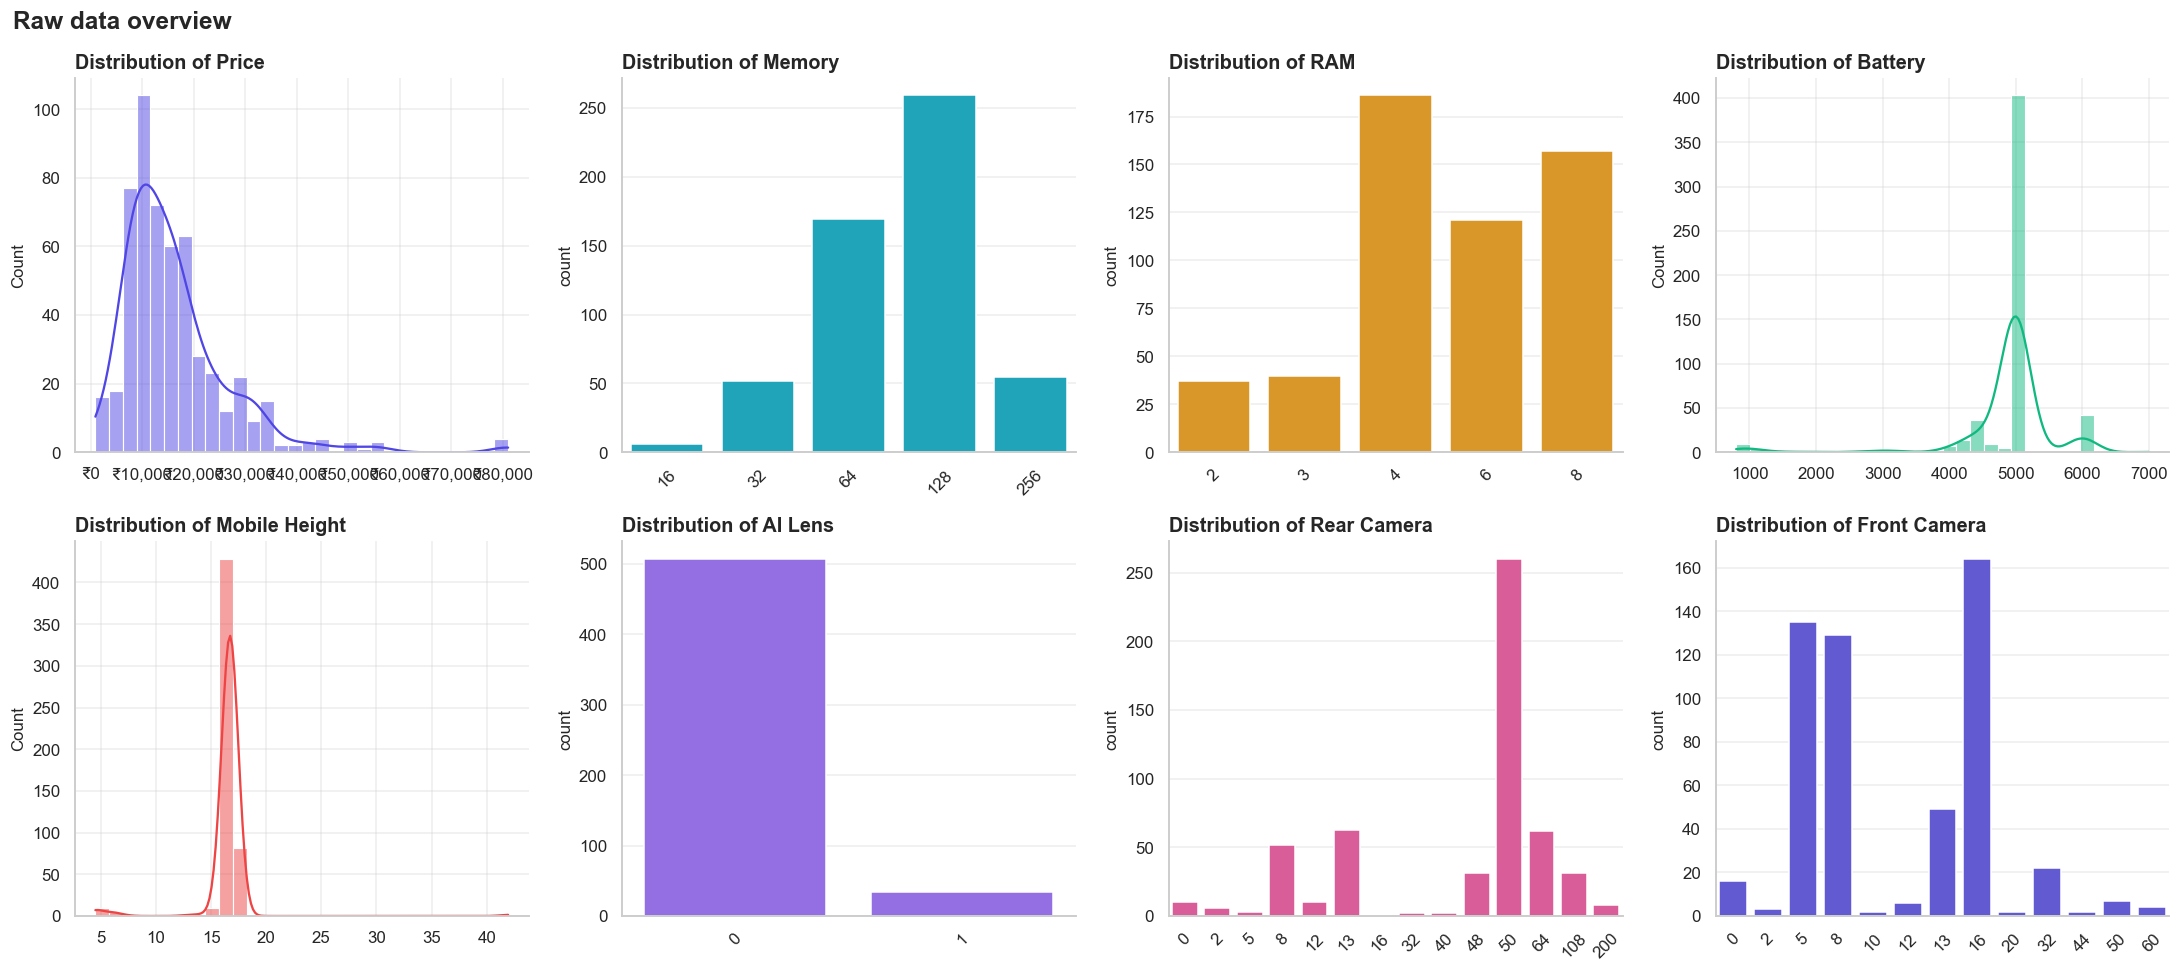

In [7]:
# Light-weight numeric copy used ONLY for these exploratory plots
explore = df_raw.copy()
explore["Price"] = pd.to_numeric(explore["Prize"].astype(str).str.replace(",", "", regex=False), errors="coerce")
for c in ["Rear Camera", "Front Camera"]:
    explore[c] = pd.to_numeric(explore[c].astype(str).str.extract(r"(\d+)", expand=False), errors="coerce")

panels = [("Price", "hist"), ("Memory", "count"), ("RAM", "count"), ("Battery_", "hist"),
          ("Mobile Height", "hist"), ("AI Lens", "count"), ("Rear Camera", "count"), ("Front Camera", "count")]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for i, (ax, (col, kind)) in enumerate(zip(axes.ravel(), panels)):
    color = PALETTE[i % len(PALETTE)]
    if kind == "hist":
        sns.histplot(explore[col].dropna(), kde=True, ax=ax, color=color, bins=30)
    else:
        order = sorted(explore[col].dropna().unique())
        sns.countplot(x=col, data=explore, order=order, ax=ax, color=color)
        ax.tick_params(axis="x", rotation=45)
    ax.set_title(f"Distribution of {col.replace('_', ' ')}")
    ax.set_xlabel("")
rupee_axis(axes[0, 0], "x")
fig.suptitle("Raw data overview", fontsize=16, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 2. Data Preprocessing

In [8]:
# Standardise names, then convert text columns into proper numbers
df = df_raw.rename(columns={
    "Battery_": "Battery", "Processor_": "Processor", "Prize": "Price",
    "Rear Camera": "Rear_Camera_MP", "Front Camera": "Front_Camera_MP",
    "AI Lens": "AI_Lens", "Mobile Height": "Mobile_Height",
}).copy()

for c in ["Model", "Colour", "Processor"]:
    df[c] = df[c].astype(str).str.strip()

# FIX #1: Price arrives as text such as "7,299" - remove the comma and convert
df["Price"] = pd.to_numeric(df["Price"].astype(str).str.replace(",", "", regex=False), errors="coerce")

for c in ["Rear_Camera_MP", "Front_Camera_MP"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.extract(r"(\d+)", expand=False), errors="coerce")

n_bad = df[["Price", "Rear_Camera_MP", "Front_Camera_MP"]].isna().sum()
print("Values that could not be converted to numbers (should all be 0):")
print(n_bad.to_string())
df.dtypes.to_frame("Data type").T

Values that could not be converted to numbers (should all be 0):
Price              0
Rear_Camera_MP     0
Front_Camera_MP    0


,Model,Colour,Memory,RAM,Battery,Rear_Camera_MP,Front_Camera_MP,AI_Lens,Mobile_Height,Processor,Price
Data type,object,object,int64,int64,int64,int64,int64,int64,float64,object,int64


### 2.1 Inconsistency & outlier handling

**Missing values:** the raw-data audit found zero missing values in every column, so no imputation or row removal for missingness was needed; the final quality gate checks this again.

**Outliers and inconsistencies:** exact duplicates and records with impossible zero-megapixel cameras or screen height below 10 cm are removed. Boxplots are used to review numeric extremes; plausible high prices and capacities are retained rather than automatically trimmed. The 41.94 cm screen-height entries are known inch-to-centimetre conversion errors and are corrected to 16.51 cm before the final range check.


In [9]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} exact duplicate rows. Remaining rows: {len(df)}")

# Physically impossible smartphone entries (feature phones / malformed rows)
corrupt_mask = (df.Rear_Camera_MP == 0) | (df.Front_Camera_MP == 0) | (df.Mobile_Height < 10)
print(f"\nCorrupted records found (0 MP camera or screen height < 10 cm): {corrupt_mask.sum()}")
display(df.loc[corrupt_mask, ["Model", "Memory", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Mobile_Height", "Price"]])

df = df.loc[~corrupt_mask].reset_index(drop=True)
print(f"Rows remaining after removal: {len(df)}")

Removed 10 exact duplicate rows. Remaining rows: 531

Corrupted records found (0 MP camera or screen height < 10 cm): 15


,Model,Memory,RAM,Battery,Rear_Camera_MP,Front_Camera_MP,Mobile_Height,Price
95,Micromax IN 2C,128,6,800,0,0,4.50,1449
105,micromax 2,128,8,1900,2,0,7.11,1849
113,micromax,128,4,1000,0,0,4.50,1422
115,micromax 1,256,8,800,0,0,4.50,1299
129,Micromax 3,128,4,1020,2,0,6.10,2615
148,micromax 3,64,4,800,2,0,5.08,2490
151,micromax 2,256,8,800,0,0,4.50,1299
152,micromax 3,256,4,1020,2,0,6.10,2499
177,micromax,32,3,2550,0,0,4.50,1375
178,micromax1,32,3,800,0,0,4.50,1599


Rows remaining after removal: 516


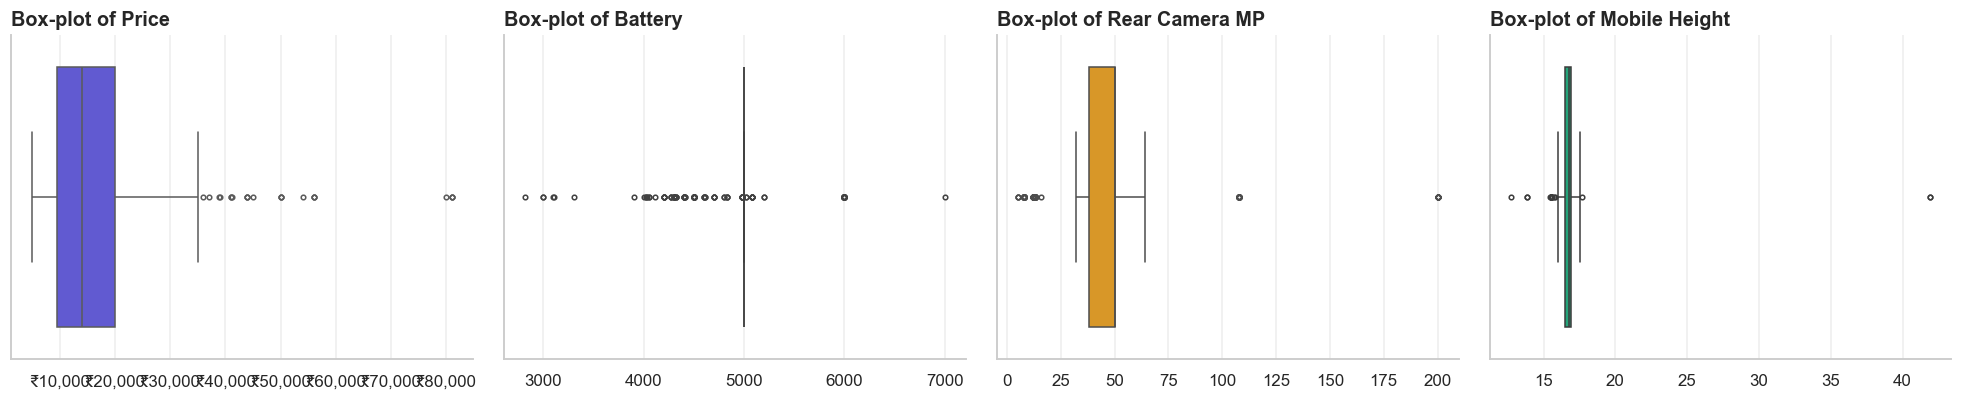

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c, colr in zip(axes, ["Price", "Battery", "Rear_Camera_MP", "Mobile_Height"], PALETTE):
    sns.boxplot(x=df[c], ax=ax, color=colr, fliersize=3)
    ax.set_title(f"Box-plot of {c.replace('_', ' ')}")
    ax.set_xlabel("")
rupee_axis(axes[0], "x")
plt.tight_layout()
plt.show()

In [11]:
# Screen height must lie in a realistic range (10 - 25 cm).
LOW_H, HIGH_H = 10, 25
bad_h = (df.Mobile_Height < LOW_H) | (df.Mobile_Height > HIGH_H)
print("Heights outside the realistic range:")
display(df.loc[bad_h, ["Model", "Mobile_Height", "Price"]])

# FIX #5: values such as 41.94 are inches->cm converted twice (16.51 in x 2.54 = 41.94). Dividing by 2.54 recovers 16.51 cm.
too_big = df.Mobile_Height > HIGH_H
df.loc[too_big, "Mobile_Height"] = (df.loc[too_big, "Mobile_Height"] / 2.54).round(2)

# Anything still impossible is set to the median
still_bad = (df.Mobile_Height < LOW_H) | (df.Mobile_Height > HIGH_H)
df.loc[still_bad, "Mobile_Height"] = df["Mobile_Height"].median()
print(f"\nCorrected {too_big.sum()} unit errors and imputed {still_bad.sum()} remaining values.")
print(f"Mobile_Height now ranges {df.Mobile_Height.min():.2f} - {df.Mobile_Height.max():.2f} cm")

Heights outside the realistic range:


,Model,Mobile_Height,Price
73,MOTOROLA G62 5G,41.94,16499
86,MOTOROLA G62 5G,41.94,16499



Corrected 2 unit errors and imputed 0 remaining values.
Mobile_Height now ranges 12.70 - 17.65 cm


### 2.2 Feature engineering & categorical cleaning

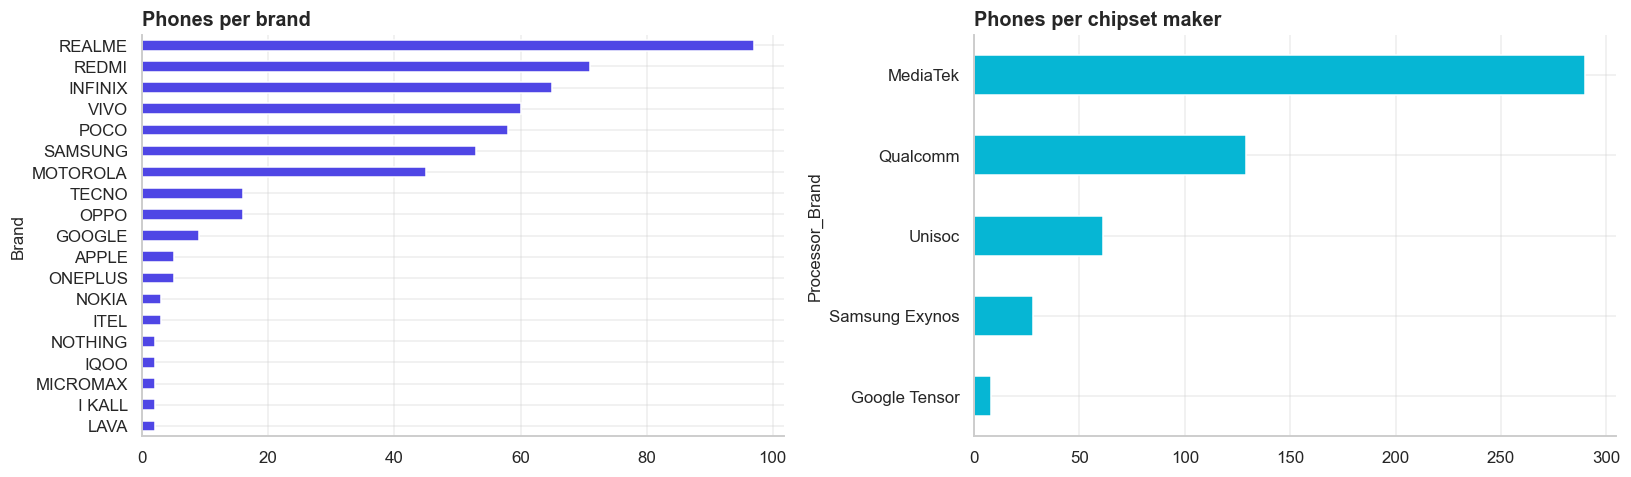

Total 5G-enabled handsets: 194  |  Unique phone models: 174


In [12]:
BRAND_FIXES = {"I": "I KALL"}   # "I Kall" was being cut to just "I"
df["Brand"] = df["Model"].str.split().str.get(0).str.upper().replace(BRAND_FIXES)

def categorize_processor(name: str) -> str:
    n = name.lower()
    if any(t in n for t in ["apple", "bionic"]):
        return "Apple"
    if "tensor" in n:
        return "Google Tensor"
    if any(t in n for t in ["snapdragon", "qualcomm"]):
        return "Qualcomm"
    if "exynos" in n:
        return "Samsung Exynos"
    if any(t in n for t in ["unisoc", "spreadtrum", "sc9863", "sc6531", "t606", "t612", "t616"]):
        return "Unisoc"
    return "MediaTek"   # Helio / Dimensity / bare names such as "G37" are MediaTek parts

df["Processor_Brand"] = df["Processor"].apply(categorize_processor)
df["Is_5G"] = (df["Model"].str.contains("5G", case=False) |
               df["Processor"].str.contains("5G|Dimensity", case=False)).astype(int)

# Group key: same phone sold in several colours / storage options must stay together when splitting
df["Model_Group"] = df["Model"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
df["Brand"].value_counts().sort_values().plot.barh(ax=axes[0], color=PALETTE[0])
axes[0].set_title("Phones per brand")
df["Processor_Brand"].value_counts().sort_values().plot.barh(ax=axes[1], color=PALETTE[1])
axes[1].set_title("Phones per chipset maker")
plt.tight_layout(); plt.show()
print(f"Total 5G-enabled handsets: {df['Is_5G'].sum()}  |  Unique phone models: {df['Model_Group'].nunique()}")

In [13]:
# Final data-quality gate: stop early if anything is still wrong
checks = {
    "No missing values": df.isna().sum().sum() == 0,
    "All prices positive": (df.Price > 0).all(),
    "Heights realistic": df.Mobile_Height.between(LOW_H, HIGH_H).all(),
    "Cameras > 0 MP": ((df.Rear_Camera_MP > 0) & (df.Front_Camera_MP > 0)).all(),
}
display(pd.Series(checks, name="Passed?").to_frame())
assert all(checks.values()), "Data-quality check failed - inspect the table above."
print(f"Clean dataset ready: {df.shape[0]} rows x {df.shape[1]} columns")

,Passed?
No missing values,True
All prices positive,True
Heights realistic,True
Cameras > 0 MP,True


Clean dataset ready: 516 rows x 15 columns


## 3. Feature Extraction & Bivariate Analysis

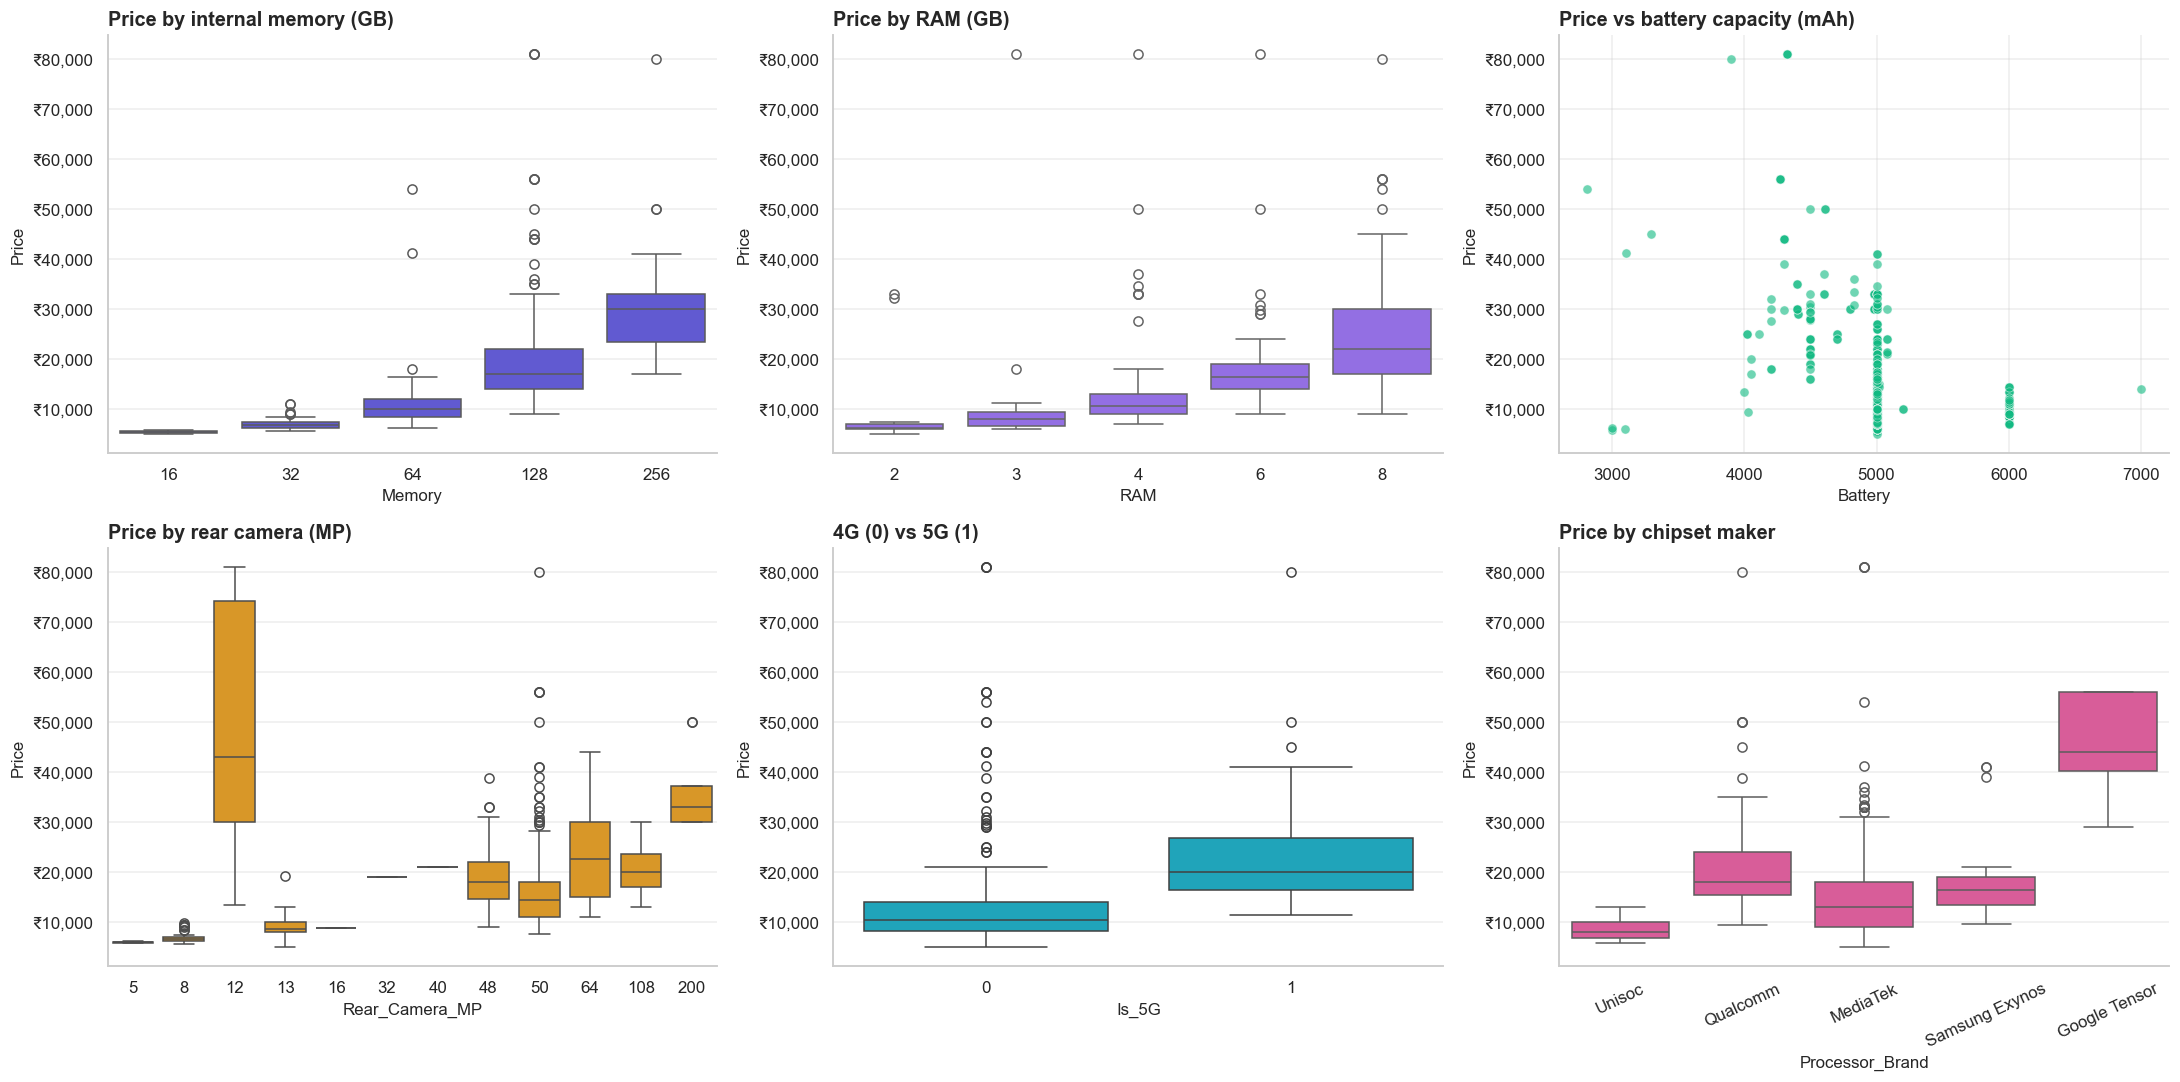

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
sns.boxplot(x="Memory", y="Price", data=df, ax=axes[0, 0], color=PALETTE[0])
axes[0, 0].set_title("Price by internal memory (GB)")
sns.boxplot(x="RAM", y="Price", data=df, ax=axes[0, 1], color=PALETTE[5])
axes[0, 1].set_title("Price by RAM (GB)")
sns.scatterplot(x="Battery", y="Price", data=df, ax=axes[0, 2], color=PALETTE[3], alpha=0.6, edgecolor="white")
axes[0, 2].set_title("Price vs battery capacity (mAh)")
sns.boxplot(x="Rear_Camera_MP", y="Price", data=df, ax=axes[1, 0], color=PALETTE[2])
axes[1, 0].set_title("Price by rear camera (MP)")
sns.boxplot(x="Is_5G", y="Price", data=df, ax=axes[1, 1], color=PALETTE[1])
axes[1, 1].set_title("4G (0) vs 5G (1)")
sns.boxplot(x="Processor_Brand", y="Price", data=df, ax=axes[1, 2], color=PALETTE[6])
axes[1, 2].set_title("Price by chipset maker"); axes[1, 2].tick_params(axis="x", rotation=25)
for ax in axes.ravel():
    rupee_axis(ax, "y")
plt.tight_layout(); plt.show()

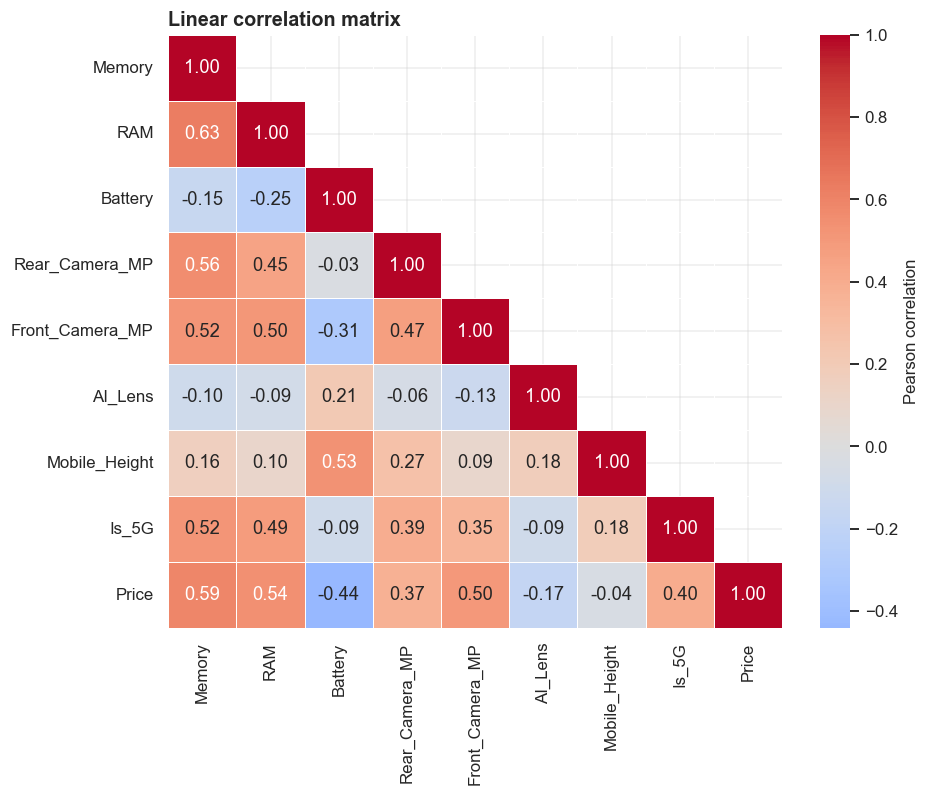

,Correlation with Price
Memory,0.592
RAM,0.544
Front_Camera_MP,0.504
Is_5G,0.398
Rear_Camera_MP,0.372
Mobile_Height,-0.037
AI_Lens,-0.171
Battery,-0.441


In [15]:
num_feats = ["Memory", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "AI_Lens", "Mobile_Height", "Is_5G"]
corr = df[num_feats + ["Price"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5,
            cbar_kws={"label": "Pearson correlation"})
plt.title("Linear correlation matrix")
plt.show()

display(corr["Price"].drop("Price").sort_values(ascending=False).round(3).to_frame("Correlation with Price"))

,F-statistic,p-value,Mutual information,Significant (p<0.05)
Front_Camera_MP,174.6,1.59e-34,0.739,Yes
Memory,276.9,4.69e-50,0.714,Yes
RAM,216.0,4.46e-41,0.699,Yes
Mobile_Height,0.7,4.04e-01,0.624,No
Rear_Camera_MP,82.3,2.46e-18,0.579,Yes
Is_5G,96.7,5.07e-21,0.318,Yes
Battery,124.0,5.93e-26,0.289,Yes
AI_Lens,15.5,9.35e-05,0.057,Yes


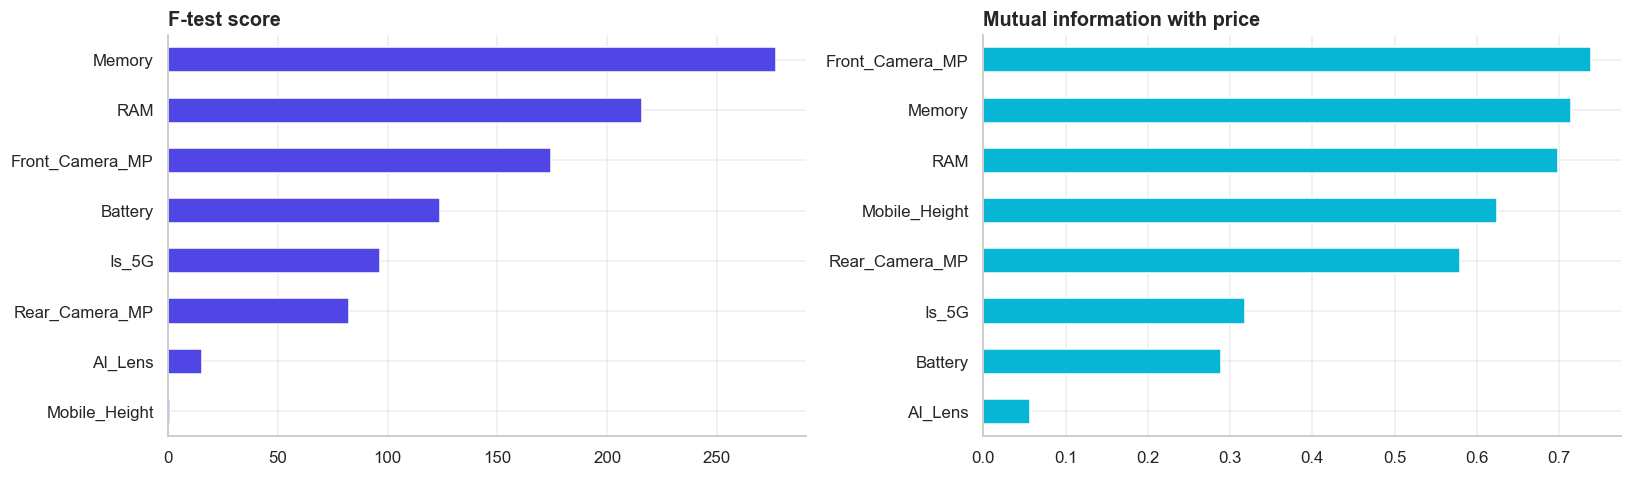

In [16]:
# Statistical tests: F-test (linear link) and mutual information (any link, including non-linear)
X_num = df[num_feats]
f_stat, f_p = f_regression(X_num, df["Price"])
mi = mutual_info_regression(X_num, df["Price"], random_state=RANDOM_STATE)

stat_df = pd.DataFrame({"F-statistic": f_stat, "p-value": f_p, "Mutual information": mi}, index=num_feats)
stat_df["Significant (p<0.05)"] = np.where(stat_df["p-value"] < 0.05, "Yes", "No")
stat_df = stat_df.sort_values("Mutual information", ascending=False)
display(stat_df.style.format({"F-statistic": "{:,.1f}", "p-value": "{:.2e}", "Mutual information": "{:.3f}"})
        .background_gradient(subset=["Mutual information", "F-statistic"], cmap="Blues"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
stat_df["F-statistic"].sort_values().plot.barh(ax=axes[0], color=PALETTE[0]); axes[0].set_title("F-test score")
stat_df["Mutual information"].sort_values().plot.barh(ax=axes[1], color=PALETTE[1]); axes[1].set_title("Mutual information with price")
plt.tight_layout(); plt.show()

In [17]:
# Categorical features: how much of the price variation does each explain? (eta-squared / ANOVA effect size)
def eta_squared(cat, target):
    g = target.groupby(cat)
    ss_between = (g.count() * (g.mean() - target.mean()) ** 2).sum()
    ss_total = ((target - target.mean()) ** 2).sum()
    return ss_between / ss_total if ss_total else 0.0

cat_feats = ["Model", "Brand", "Processor", "Processor_Brand", "Colour"]
eta = pd.DataFrame({
    "Variance explained (η²)": {c: eta_squared(df[c], df["Price"]) for c in cat_feats},
    "Unique values": df[cat_feats].nunique(),
}).sort_values("Variance explained (η²)", ascending=False)
display(eta.style.format({"Variance explained (η²)": "{:.1%}"}).background_gradient(subset=["Variance explained (η²)"], cmap="Purples"))
print("Note: η² rises automatically with the number of unique values, so 'Model' and 'Processor' look strong "
      "but would overfit. The model therefore uses Brand and Processor_Brand instead.")

,Variance explained (η²),Unique values
Model,99.2%,179
Processor,94.9%,116
Colour,86.8%,275
Brand,47.8%,19
Processor_Brand,22.1%,5


Note: η² rises automatically with the number of unique values, so 'Model' and 'Processor' look strong but would overfit. The model therefore uses Brand and Processor_Brand instead.


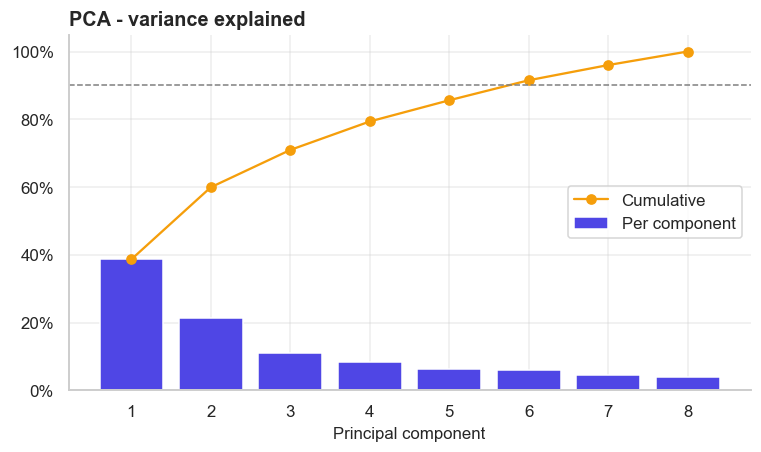

6 of 8 components capture 90% of the variance, so the specs carry mostly distinct information. All original features are kept for interpretability.


In [18]:
# PCA: do the numeric specs overlap, i.e. can they be compressed?
pca = PCA().fit(StandardScaler().fit_transform(X_num))
cum = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color=PALETTE[0], label="Per component")
ax.plot(range(1, len(cum) + 1), cum, marker="o", color=PALETTE[2], label="Cumulative")
ax.axhline(0.9, ls="--", color="grey", lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Principal component"); ax.set_title("PCA - variance explained"); ax.legend()
plt.show()
print(f"{int(np.argmax(cum >= 0.9)) + 1} of {len(cum)} components capture 90% of the variance, "
      "so the specs carry mostly distinct information. All original features are kept for interpretability.")

### Feature-selection decision

The numeric screening ranks front-camera resolution, storage (`Memory`), and RAM highest by mutual information (0.739, 0.714, and 0.699). The model-based feature-importance check later provides an independent comparison. Categorical η² is high for `Model`, `Processor`, and `Colour`, but those columns have many unique values and can encode near-identifiers or repeated variants. The prediction pipeline therefore keeps the more general `Brand` and `Processor_Brand` categories and excludes `Model`, `Colour`, and raw `Processor` from predictors. PCA shows that 6 of 8 numeric components are needed to explain 90% of variance, so the notebook retains the original numeric specifications for interpretability instead of compressing them. These rankings are screening evidence, not causal effects.


## 4. Model Building & Validation
**Leakage control:** the same phone is listed in several colours and storage options with near-identical specs and price.
A random split would place "twins" in both training and test sets and flatter the scores. Here every phone **model** stays entirely in either
training or test data, which mimics predicting the price of a phone the company has never seen.

In [19]:
FEATURES = ["Memory", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "AI_Lens", "Mobile_Height", "Is_5G", "Brand", "Processor_Brand"]
NUM = ["Memory", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "AI_Lens", "Mobile_Height"]
CAT = ["Brand", "Processor_Brand"]

X, y, groups = df[FEATURES], df["Price"], df["Model_Group"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx]), "Leakage: a model appears in both sets"
print(f"Training rows: {len(X_train)}  |  Test rows: {len(X_test)}  |  Models shared between sets: 0")

def build_pipeline(regressor):
    pre = ColumnTransformer([
        ("numeric", StandardScaler(), NUM),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])
    return Pipeline([("preprocessing", pre), ("estimator", regressor)])

cv = GroupKFold(n_splits=5)

Training rows: 411  |  Test rows: 105  |  Models shared between sets: 0


### 4.1 Baseline comparison of all candidate algorithms

In [20]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, est in candidates.items():
    res = cross_validate(build_pipeline(est), X_train, y_train, groups=g_train, cv=cv, n_jobs=-1,
                         scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rows.append({"Model": name, "CV MAE (₹)": -res["test_mae"].mean(),
                 "CV RMSE (₹)": -res["test_rmse"].mean(), "CV R²": res["test_r2"].mean()})

baseline_df = pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE (₹)")
banner("Baseline models - 5-fold cross-validation on training data (grouped by phone model)")
display(baseline_df.style.format({"CV MAE (₹)": "₹{:,.0f}", "CV RMSE (₹)": "₹{:,.0f}", "CV R²": "{:.3f}"})
        .background_gradient(subset=["CV RMSE (₹)"], cmap="RdYlGn_r").background_gradient(subset=["CV R²"], cmap="RdYlGn"))

<div style="background:#4F46E5;color:white;padding:10px 16px;border-radius:8px;font-weight:600;font-size:15px;">Baseline models - 5-fold cross-validation on training data (grouped by phone model)</div>

,CV MAE (₹),CV RMSE (₹),CV R²
Model,,,
Gradient Boosting,"₹3,660","₹6,528",0.647
Linear Regression,"₹4,069","₹6,577",0.631
Ridge Regression,"₹4,160","₹6,627",0.640
Random Forest,"₹4,158","₹7,013",0.595
Decision Tree,"₹4,665","₹7,855",0.481


### 4.2 Hyper-parameter tuning (tree ensembles)

In [21]:
param_grids = {
    "Random Forest": {"estimator__n_estimators": [100, 200], "estimator__max_depth": [None, 6, 10]},
    "Gradient Boosting": {"estimator__n_estimators": [100, 200], "estimator__learning_rate": [0.05, 0.1],
                          "estimator__max_depth": [3, 5]},
}

tuned_models, tuned_cv_rmse = {}, {}
for name, grid in param_grids.items():
    search = GridSearchCV(build_pipeline(candidates[name]), grid, cv=cv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X_train, y_train, groups=g_train)          # groups keep each phone model inside one fold
    tuned_models[f"Tuned {name}"] = search.best_estimator_
    tuned_cv_rmse[f"Tuned {name}"] = -search.best_score_
    print(f"{name:18s} best params: {search.best_params_}  ->  CV RMSE ₹{-search.best_score_:,.0f}")

Random Forest      best params: {'estimator__max_depth': 6, 'estimator__n_estimators': 200}  ->  CV RMSE ₹6,919
Gradient Boosting  best params: {'estimator__learning_rate': 0.05, 'estimator__max_depth': 3, 'estimator__n_estimators': 100}  ->  CV RMSE ₹6,291


### 4.3 Final evaluation on unseen phone models

In [22]:
# FIX #7: the winner is chosen from cross-validation on TRAINING data; the test set is used only to report results.
champion_name = min(tuned_cv_rmse, key=tuned_cv_rmse.get)
final_pipeline = tuned_models[champion_name]

records = []
for name, pipe in tuned_models.items():
    s = regression_scores(y_test, pipe.predict(X_test))
    s["CV RMSE (₹)"] = tuned_cv_rmse[name]
    s["Selected"] = "★ Champion" if name == champion_name else ""
    records.append({"Model": name, **s})

results_df = pd.DataFrame(records).set_index("Model")
banner(f"Selected model: {champion_name}", "#10B981")
display(results_df.style.format({"MAE (₹)": "₹{:,.0f}", "RMSE (₹)": "₹{:,.0f}", "CV RMSE (₹)": "₹{:,.0f}", "R²": "{:.3f}"})
        .background_gradient(subset=["R²"], cmap="Greens"))

<div style="background:#10B981;color:white;padding:10px 16px;border-radius:8px;font-weight:600;font-size:15px;">Selected model: Tuned Gradient Boosting</div>

,MAE (₹),RMSE (₹),R²,CV RMSE (₹),Selected
Model,,,,,
Tuned Random Forest,"₹3,124","₹4,619",0.666,"₹6,919",
Tuned Gradient Boosting,"₹2,737","₹4,033",0.745,"₹6,291",★ Champion


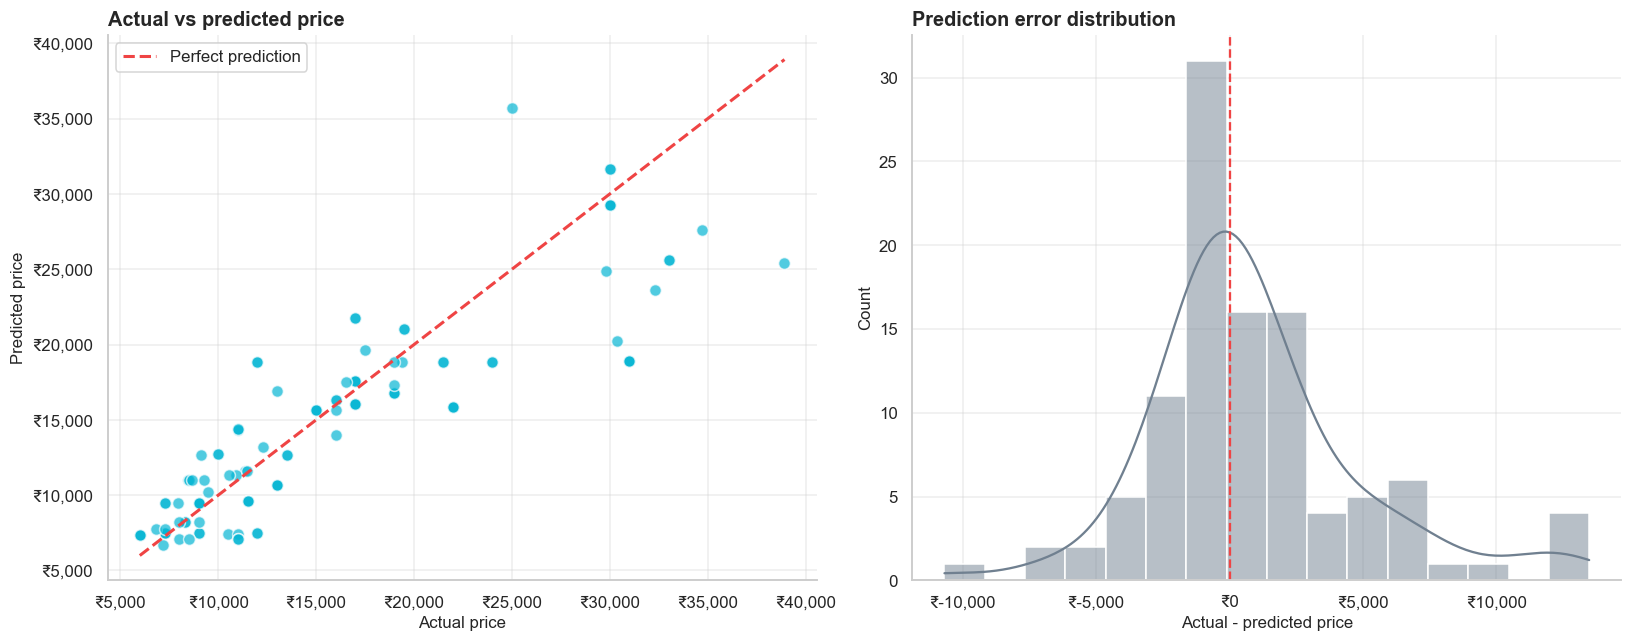

In [23]:
final_predictions = final_pipeline.predict(X_test)
residuals = y_test - final_predictions

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(y_test, final_predictions, alpha=0.7, color=PALETTE[1], edgecolors="white", s=60)
lims = [min(y_test.min(), final_predictions.min()), max(y_test.max(), final_predictions.max())]
axes[0].plot(lims, lims, "--", color=PALETTE[4], linewidth=2, label="Perfect prediction")
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title("Actual vs predicted price"); axes[0].legend()
rupee_axis(axes[0], "x"); rupee_axis(axes[0], "y")

sns.histplot(residuals, kde=True, ax=axes[1], color="slategray")          # FIX #2: valid colour name
axes[1].axvline(0, color=PALETTE[4], ls="--")
axes[1].set_title("Prediction error distribution"); axes[1].set_xlabel("Actual - predicted price")
rupee_axis(axes[1], "x")
plt.tight_layout(); plt.show()

### 4.4 Generalisation check - all data, every fold is a set of unseen phone models

In [24]:
oof = cross_val_predict(final_pipeline, X, y, cv=GroupKFold(n_splits=5), groups=groups)
gen = regression_scores(y, oof)

display(pd.DataFrame(gen, index=["Out-of-group cross-validation"]).style.format(
    {"MAE (₹)": "₹{:,.0f}", "RMSE (₹)": "₹{:,.0f}", "R²": "{:.3f}"}))

,MAE (₹),RMSE (₹),R²
Out-of-group cross-validation,"₹3,546","₹6,835",0.592


## 5. Feature Importance

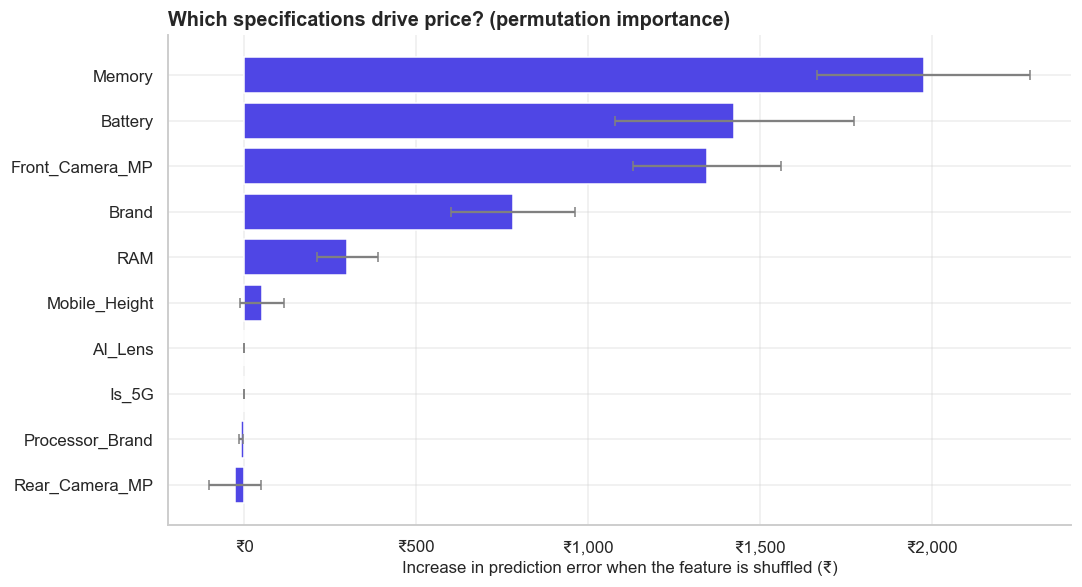

,RMSE increase (₹),Std dev
Memory,"₹1,977",₹310
Battery,"₹1,425",₹348
Front_Camera_MP,"₹1,345",₹215
Brand,₹781,₹180
RAM,₹300,₹88
Mobile_Height,₹51,₹63
AI_Lens,₹0,₹0
Is_5G,₹0,₹0
Processor_Brand,₹-10,₹6
Rear_Camera_MP,₹-26,₹75


In [25]:
perm = permutation_importance(final_pipeline, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)

importance_df = pd.DataFrame({"RMSE increase (₹)": perm.importances_mean, "Std dev": perm.importances_std},
                             index=X_test.columns).sort_values("RMSE increase (₹)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df = importance_df.iloc[::-1]
ax.barh(plot_df.index, plot_df["RMSE increase (₹)"], xerr=plot_df["Std dev"], color=PALETTE[0], ecolor="grey", capsize=3)
ax.set_xlabel("Increase in prediction error when the feature is shuffled (₹)")
ax.set_title("Which specifications drive price? (permutation importance)")
rupee_axis(ax, "x")
plt.tight_layout(); plt.show()

display(importance_df.style.format("₹{:,.0f}").background_gradient(subset=["RMSE increase (₹)"], cmap="Blues"))

### 5.1 Cross-check: feature extraction vs. model importance

The top univariate mutual-information features are front-camera resolution (0.739), storage (`Memory`, 0.714), and RAM (0.699). On the held-out set, permutation importance ranks storage first (RMSE increase ₹1,977), battery second (₹1,425), and front-camera resolution third (₹1,345). Storage and front-camera resolution are supported by both analyses; battery adds a strong model-based signal, while RAM has a strong univariate association but a smaller conditional contribution (₹300). The agreement supports the feature-screening conclusions while the different rankings show why both analyses are useful. These are predictive associations and do not establish that changing one specification alone will cause a particular price increase.


## 6. Business Insights & Recommendations

In [26]:
top = importance_df["RMSE increase (₹)"].head(3).index.tolist()
display(Markdown(f"""
### Headline findings (generated from the results above)
- **Model quality:** the {champion_name} predicts price to within about **₹{results_df.loc[champion_name, "MAE (₹)"]:,.0f}** on average
  (R² = {results_df.loc[champion_name, "R²"]:.2f}) for phone models it has never seen.
- **Top price drivers:** **{top[0]}**, **{top[1]}** and **{top[2]}**.
- **5G premium:** 5G phones have a median price of **₹{df.loc[df.Is_5G == 1, "Price"].median():,.0f}**
  versus **₹{df.loc[df.Is_5G == 0, "Price"].median():,.0f}** for 4G phones.
"""))

summary = pd.DataFrame({
    "Median price by RAM (₹)": df.groupby("RAM")["Price"].median(),
    "Phones": df.groupby("RAM")["Price"].size(),
})
display(summary.style.format({"Median price by RAM (₹)": "₹{:,.0f}"}).background_gradient(subset=["Median price by RAM (₹)"], cmap="Oranges"))

brand_tbl = (df.groupby("Brand")["Price"].agg(["count", "median"]).query("count >= 5")
             .sort_values("median", ascending=False).rename(columns={"count": "Phones", "median": "Median price (₹)"}))
display(brand_tbl.style.format({"Median price (₹)": "₹{:,.0f}"}).background_gradient(subset=["Median price (₹)"], cmap="Purples"))


### Headline findings (generated from the results above)
- **Model quality:** the Tuned Gradient Boosting predicts price to within about **₹2,737** on average
  (R² = 0.75) for phone models it has never seen.
- **Top price drivers:** **Memory**, **Battery** and **Front_Camera_MP**.
- **5G premium:** 5G phones have a median price of **₹19,999**
  versus **₹10,499** for 4G phones.


,Median price by RAM (₹),Phones
RAM,,
2,"₹6,299",37
3,"₹8,024",38
4,"₹10,699",172
6,"₹16,499",118
8,"₹21,999",151


,Phones,Median price (₹)
Brand,,
APPLE,5,"₹80,999"
GOOGLE,9,"₹43,999"
ONEPLUS,5,"₹28,298"
VIVO,60,"₹17,999"
SAMSUNG,53,"₹16,999"
REDMI,71,"₹14,999"
POCO,58,"₹14,499"
OPPO,16,"₹14,249"
MOTOROLA,45,"₹13,999"


### How to use this analysis
1. **Pricing new launches** – enter the specification sheet into the prediction function in section 7 to get a data-backed reference price, then adjust for brand positioning.
2. **Spotting mis-priced stock** – compare the model's estimate with the current list price. Large gaps flag phones that are over- or under-priced for their specifications.
3. **Range planning** – invest in the features ranked highest in section 5; they are what the market actually pays for.
4. **Data upkeep** – retrain when new models are added. Feature phones were excluded, so the model should not be used for them.

**Known limitations:** the data covers a single marketplace snapshot, brands with few listings (for example Apple or Google) are predicted less reliably,
and factors such as discounts, launch date and reviews are not in the data.

### Recommendations for pricing and marketing

1. **Build specification-led price tiers.** Storage, battery capacity, and front-camera resolution are the strongest held-out model drivers in this run. Use these features to define and explain good/better/best product bundles, then compare like-for-like models before setting a premium.
2. **Use the observed RAM ladder as a reference, not a guaranteed upgrade premium.** Median prices are ₹6,299 for 2 GB RAM (37 phones), ₹10,699 for 4 GB (172), ₹16,499 for 6 GB (118), and ₹21,999 for 8 GB (151). Check brand, storage, and model mix before using these gaps to set a launch price.
3. **Use the prediction as a starting point and retain a pricing buffer.** The selected model's held-out MAE is about ₹2,737, so validate suggested prices against current competitors and commercial constraints before launch.
4. **Make marketing claims around the features the evidence supports, then test them.** Emphasize memory, battery, and front-camera comparisons where relevant; use controlled pricing or campaign tests to estimate incremental sales or price effects, since this observational dataset cannot establish causality.


## 7. Model Deployment & Live Inference

In [27]:
MODEL_FILE = "phone_price_predictor_pipeline.pkl"
with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_pipeline, f)
print(f"Model saved to '{MODEL_FILE}' ({os.path.getsize(MODEL_FILE) / 1024:,.0f} KB).")

# Option lists and typical error, used by the interactive predictor and the standalone app
import json
metadata = {
    "brands": sorted(df["Brand"].unique().tolist()),
    "processor_brands": sorted(df["Processor_Brand"].unique().tolist()),
    "memory": sorted(int(v) for v in df["Memory"].unique()),
    "ram": sorted(int(v) for v in df["RAM"].unique()),
    "rear_camera_mp": sorted(int(v) for v in df["Rear_Camera_MP"].unique()),
    "front_camera_mp": sorted(int(v) for v in df["Front_Camera_MP"].unique()),
    "battery_range": [int(df["Battery"].min()), int(df["Battery"].max())],
    "height_range": [float(df["Mobile_Height"].min()), float(df["Mobile_Height"].max())],
    "typical_error_inr": float(results_df.loc[champion_name, "MAE (₹)"]),
    "price_range_inr": [float(df["Price"].min()), float(df["Price"].max())],
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print("Option lists saved to 'model_metadata.json'.")

Model saved to 'phone_price_predictor_pipeline.pkl' (136 KB).
Option lists saved to 'model_metadata.json'.


In [28]:
def predict_price(specs: dict, model_file: str = MODEL_FILE) -> float:
    """Return the predicted price (₹) for one phone specification dictionary."""
    missing = [f for f in FEATURES if f not in specs]
    if missing:
        raise ValueError(f"Missing specification(s): {missing}")
    with open(model_file, "rb") as f:
        model = pickle.load(f)
    row = pd.DataFrame([{k: specs[k] for k in FEATURES}])
    return max(0.0, float(model.predict(row)[0]))

example_phone = {
    "Memory": 128, "RAM": 6, "Battery": 5000, "Rear_Camera_MP": 50.0, "Front_Camera_MP": 16.0,
    "AI_Lens": 0, "Mobile_Height": 16.5, "Is_5G": 1, "Brand": "POCO", "Processor_Brand": "MediaTek",
}
price = predict_price(example_phone)
banner(f"Predicted price for the example specification: ₹{price:,.0f}", "#4F46E5")

<div style="background:#4F46E5;color:white;padding:10px 16px;border-radius:8px;font-weight:600;font-size:15px;">Predicted price for the example specification: ₹16,341</div>

## 8. 📱 Interactive Mobile Price Predictor
Choose the specifications below and click **Predict price**. The estimate comes from the trained model saved above.

In [29]:
import ipywidgets as widgets

W = {"description_width": "130px"}
L = widgets.Layout(width="420px")
w_brand = widgets.Dropdown(options=metadata["brands"], description="Brand", style=W, layout=L)
w_proc  = widgets.Dropdown(options=metadata["processor_brands"], description="Chipset maker", style=W, layout=L)
w_mem   = widgets.Dropdown(options=metadata["memory"], value=128 if 128 in metadata["memory"] else metadata["memory"][0],
                           description="Storage (GB)", style=W, layout=L)
w_ram   = widgets.Dropdown(options=metadata["ram"], value=6 if 6 in metadata["ram"] else metadata["ram"][0],
                           description="RAM (GB)", style=W, layout=L)
w_bat   = widgets.IntSlider(value=5000, min=metadata["battery_range"][0], max=metadata["battery_range"][1], step=100,
                            description="Battery (mAh)", style=W, layout=L, continuous_update=False)
w_rear  = widgets.Dropdown(options=metadata["rear_camera_mp"], value=50 if 50 in metadata["rear_camera_mp"] else metadata["rear_camera_mp"][0],
                           description="Rear camera (MP)", style=W, layout=L)
w_front = widgets.Dropdown(options=metadata["front_camera_mp"], value=16 if 16 in metadata["front_camera_mp"] else metadata["front_camera_mp"][0],
                           description="Front camera (MP)", style=W, layout=L)
w_h     = widgets.FloatSlider(value=16.5, min=round(metadata["height_range"][0], 1), max=round(metadata["height_range"][1], 1),
                              step=0.1, description="Screen height (cm)", style=W, layout=L, continuous_update=False)
w_5g    = widgets.Checkbox(value=True, description="5G enabled", indent=False)
w_ai    = widgets.Checkbox(value=False, description="AI lens", indent=False)
btn     = widgets.Button(description="Predict price", button_style="primary", icon="calculator", layout=widgets.Layout(width="200px", height="40px"))
out     = widgets.Output()

def on_predict(_):
    specs = {"Memory": w_mem.value, "RAM": w_ram.value, "Battery": w_bat.value,
             "Rear_Camera_MP": float(w_rear.value), "Front_Camera_MP": float(w_front.value),
             "AI_Lens": int(w_ai.value), "Mobile_Height": w_h.value, "Is_5G": int(w_5g.value),
             "Brand": w_brand.value, "Processor_Brand": w_proc.value}
    p = predict_price(specs)
    e = metadata["typical_error_inr"]
    with out:
        out.clear_output()
        display(Markdown(
            f'<div style="background:linear-gradient(135deg,#4F46E5,#06B6D4);color:white;padding:18px 24px;border-radius:12px;max-width:420px;">'
            f'<div style="font-size:13px;opacity:.85;">Estimated market price</div>'
            f'<div style="font-size:34px;font-weight:700;">₹{p:,.0f}</div>'
            f'<div style="font-size:13px;opacity:.85;">Likely range: ₹{max(0, p - e):,.0f} - ₹{p + e:,.0f} (typical error ±₹{e:,.0f})</div></div>'))

btn.on_click(on_predict)
display(widgets.VBox([w_brand, w_proc, w_mem, w_ram, w_bat, w_rear, w_front, w_h,
                      widgets.HBox([w_5g, w_ai]), btn, out]))